# **VGGT depth-head fine-tuning**

# Part A — Setup (run at the start of every session)

Colab starts every session with an empty machine, so this part prepares everything first.

**A1. GPU.** Checks which GPU we got. All our runs use an A100, so the output should show an A100 and `bfloat16 supported: True`.

**A2. Google Drive and paths.** The Colab disk is erased at the end of every session, so everything that has to last (data, checkpoints, results, figures, logs) is stored on Google Drive. The last line lists the project folder on Drive.

**A3. Code and dependencies.** Downloads the official VGGT code and installs the libraries it needs. We don't use the repository's own install command, because it breaks NumPy on Colab. The output should show `vggt import OK` and `inference dtype: torch.bfloat16`.

### A1. GPU

In [1]:
import torch
print(torch.__version__, '| cuda:', torch.cuda.is_available())
GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEM_GB = torch.cuda.get_device_properties(0).total_memory / 1e9
BF16_OK = torch.cuda.get_device_capability()[0] >= 8
print(f'{GPU_NAME} | {GPU_MEM_GB:.0f} GB | bfloat16 supported: {BF16_OK}')

2.11.0+cu130 | cuda: True
NVIDIA A100-SXM4-40GB | 42 GB | bfloat16 supported: True


### A2. Google Drive and paths

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, json, shutil, subprocess, sys
PROJECT      = '/content/drive/MyDrive/vggt-depth-finetune'
DATA_DRIVE   = f'{PROJECT}/data'
RAW_TARS     = f'{DATA_DRIVE}/raw_tars'                 # vkitti_rgb.tar, vkitti_depth.tar, vkitti_textgt.tar.gz
KITTI_ROOT   = f'{DATA_DRIVE}/kitti_subset'             # real KITTI subset (Part C2)
PRETRAINED_CKPT = f'{DATA_DRIVE}/vggt_1b_checkpoint.pt' # pretrained weights, saved in Part E
CKPT_DIR     = f'{PROJECT}/checkpoints'
RESULTS_DIR  = f'{PROJECT}/results'
FIG_DIR      = f'{PROJECT}/figures'
LOG_DIR      = f'{PROJECT}/logs'

# local (fast) copies used during the session
VKITTI_TRAIN = '/content/vkitti_train'
VKITTI_VAL   = '/content/vkitti_val'
REPO         = '/content/vggt_repo'

for d in [KITTI_ROOT, CKPT_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)
print('Drive project folder:', sorted(os.listdir(PROJECT)))

Mounted at /content/drive
Drive project folder: ['checkpoints', 'checkpoints_backup', 'data', 'figures', 'logs', 'results', 'vggt']


### A3. Code and dependencies

In [3]:
if not os.path.isdir(REPO):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/facebookresearch/vggt.git', REPO], check=True)
!pip install -q einops huggingface_hub safetensors hydra-core omegaconf fvcore iopath wcmatch remotezip tensorboard

sys.path.insert(0, REPO)
os.environ['PYTHONPATH'] = REPO + ':' + os.environ.get('PYTHONPATH', '')

import numpy as np
from vggt.models.vggt import VGGT
from vggt.utils.load_fn import load_and_preprocess_images
from vggt.utils.pose_enc import pose_encoding_to_extri_intri
print('numpy', np.__version__, '| vggt import OK')

device = 'cuda'
dtype = torch.bfloat16 if BF16_OK else torch.float16
print('inference dtype:', dtype)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
numpy 2.1.3 | vggt import OK
inference dtype: torch.bfloat16


# Part B — Replication on an example scene (run once)

Before using driving data, we check that VGGT runs correctly in our setup, on an example scene from the official code: 25 photos of a LEGO bulldozer on a table. The scene has no ground truth, so the check is visual.

**B1. Running the model.** All 25 photos go through the model in one forward pass, and we use the camera, depth and point map heads. The output should show 25 frames with depth and point maps of $350 \times 518$ pixels. The figure shows the first photo, its predicted depth (lighter is closer) and its confidence (yellow is higher). The bulldozer should stand out from the table, with lower confidence in the background and along its edges.

**B2. 3D reconstruction.** We combine the predicted depth with the predicted cameras to get a 3D point for every pixel, keep the most confident half, and draw the scene from above. The bulldozer and the table should be in the middle, the 25 cameras around them, and the first camera (blue star) at the origin.

Both figures are saved on Drive (`phase1_kitchen.png`, `phase1_pointcloud.png`) and used in Section 4 of the report.

### B1. Running the model

config.json:   0%|          | 0.00/62.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 5.03GB            

model.safetensors: downloading bytes:           |  0.00B            

frames: 25 | depth (1, 25, 350, 518, 1) | points (1, 25, 350, 518, 3) | extrinsic (1, 25, 3, 4)


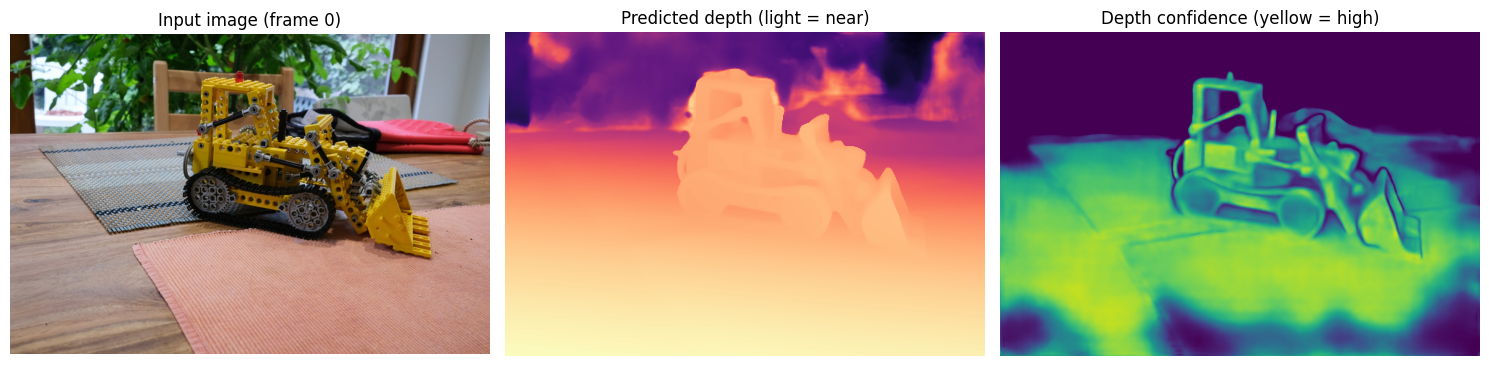

In [4]:
import matplotlib.pyplot as plt
from PIL import Image
from vggt.utils.geometry import unproject_depth_map_to_point_map

model = VGGT.from_pretrained('facebook/VGGT-1B').to(device).eval()

names = sorted(glob.glob(f'{REPO}/examples/kitchen/images/*.png'))
images = load_and_preprocess_images(names).to(device)[None]
with torch.no_grad():
    with torch.autocast('cuda', dtype=dtype):
        tokens, ps_idx = model.aggregator(images)
    pose_enc = model.camera_head(tokens)[-1]
    extrinsic, intrinsic = pose_encoding_to_extri_intri(pose_enc, images.shape[-2:])
    depth_map, depth_conf = model.depth_head(tokens, images, ps_idx)
    point_map, point_conf = model.point_head(tokens, images, ps_idx)
print('frames:', len(names), '| depth', tuple(depth_map.shape), '| points', tuple(point_map.shape),
      '| extrinsic', tuple(extrinsic.shape))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(Image.open(names[0])); ax[0].set_title('Input image (frame 0)')
ax[1].imshow(depth_map[0, 0, ..., 0].float().cpu(), cmap='magma_r'); ax[1].set_title('Predicted depth (light = near)')
ax[2].imshow(depth_conf[0, 0].float().cpu(), cmap='viridis'); ax[2].set_title('Depth confidence (yellow = high)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/phase1_kitchen.png', dpi=150); plt.show()

del model, tokens; torch.cuda.empty_cache()

### B2. 3D reconstruction.

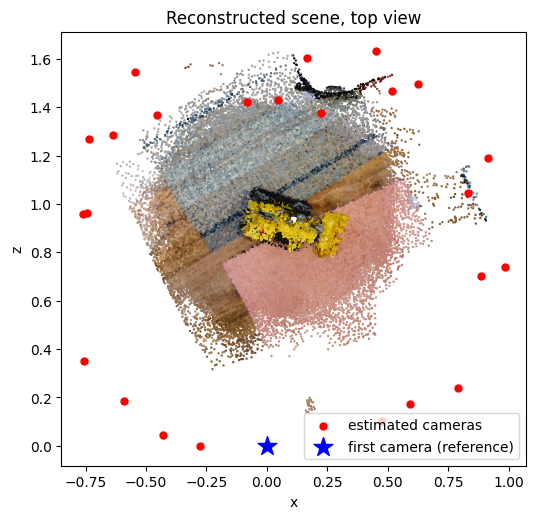

In [5]:
# B2. Top view of the reconstructed kitchen scene + the estimated cameras
pts  = unproject_depth_map_to_point_map(depth_map.squeeze(0).float().cpu(),
                                        extrinsic.squeeze(0).float().cpu(),
                                        intrinsic.squeeze(0).float().cpu())      # (25, H, W, 3)
rgb  = images[0].permute(0, 2, 3, 1).float().cpu().numpy()                       # colours of each pixel
conf = depth_conf[0].float().cpu().numpy()
keep = conf > np.percentile(conf, 50)                                            # keep the most confident half
P, C = pts[keep][::20], rgb[keep][::20]                                          # 1 point in 20, to keep the plot light

ext = extrinsic[0].float().cpu().numpy()                                         # world -> camera
cam = np.stack([-e[:, :3].T @ e[:, 3] for e in ext])                             # camera centres in 3D

plt.figure(figsize=(6, 6))
plt.scatter(P[:, 0], P[:, 2], c=C, s=0.5)
plt.scatter(cam[:, 0], cam[:, 2], c='red', s=25, label='estimated cameras')
plt.scatter(cam[0, 0], cam[0, 2], c='blue', marker='*', s=200, label='first camera (reference)')
plt.gca().set_aspect('equal'); plt.xlabel('x'); plt.ylabel('z'); plt.legend()
plt.title('Reconstructed scene, top view')
plt.savefig(f'{FIG_DIR}/phase1_pointcloud.png', dpi=150); plt.show()

# Part C — Data (slow the first time, fast afterwards)

All data is stored on Google Drive. The first run takes a while; later sessions take a minute or two.

**C1. Virtual KITTI 2.** Scenes 01, 06, 18 and 20 for training, Scene02 for testing (left camera, `clone` version). The first time, missing scenes are extracted from the original archives and the prepared data is packed into **one archive on Drive**, because Drive is very slow with thousands of small files. In later sessions, only this archive is copied to the local disk and unpacked. The cell also deletes the file list cached by VGGT's data loader (`sequence_list.txt`), so the loader always sees the current scenes. All five scenes should be marked as complete.

**C2. Real KITTI.** Three **test drives** and three **validation drives** (used only to choose the epoch), with images from the left colour camera and LiDAR ground truth. Instead of downloading the full archives (about 190 GB), `remotezip` reads only the files we need, a few hundred MB. A `DONE` file marks each finished drive, so an interrupted download continues where it stopped. Each drive has a few more images than depth maps, because KITTI has no ground truth for the first and last five frames.

### C1. Virtual KITTI 2

In [4]:
TRAIN_SCENES = ['Scene01', 'Scene06', 'Scene18', 'Scene20']
VAL_SCENES   = ['Scene02']
SPLITS = {'vkitti_train': TRAIN_SCENES, 'vkitti_val': VAL_SCENES}
PACKED = f'{DATA_DRIVE}/vkitti_prepared.tar'      # one big file = fast to copy

def scene_ok(root, s):
    b = f'{root}/{s}/clone'
    n_rgb = len(glob.glob(f'{b}/frames/rgb/Camera_0/*.jpg'))
    n_dep = len(glob.glob(f'{b}/frames/depth/Camera_0/*.png'))
    return os.path.exists(f'{b}/intrinsic.txt') and os.path.exists(f'{b}/extrinsic.txt') and n_rgb > 0 and n_rgb == n_dep, n_rgb, n_dep

if os.path.exists(PACKED):
    # ---------- FAST PATH (every session after the first) ----------
    print('Restoring from', PACKED)
    shutil.rmtree(VKITTI_TRAIN, ignore_errors=True); shutil.rmtree(VKITTI_VAL, ignore_errors=True)
    subprocess.run(['tar', '-xf', PACKED, '-C', '/content'], check=True)
else:
    # ---------- SLOW PATH (first time only) ----------
    missing = []
    for split, scenes in SPLITS.items():
        for s in scenes:
            ok, n_rgb, n_dep = scene_ok(f'{DATA_DRIVE}/{split}', s)
            print(f'{split:13s} {s}: {"OK" if ok else "MISSING/INCOMPLETE"}  rgb={n_rgb} depth={n_dep}')
            if not ok: missing.append((split, s))

    if missing:
        print('\nExtracting missing scenes from the raw tars (10-20 min)...')
        tmp = '/content/vkitti_extract'; os.makedirs(tmp, exist_ok=True)
        scenes = [s for _, s in missing]
        subprocess.run(['tar', '-xf', f'{RAW_TARS}/vkitti_rgb.tar', '-C', tmp, '--wildcards'] +
                       [f'{s}/clone/frames/rgb/Camera_0/*' for s in scenes], check=True)
        subprocess.run(['tar', '-xf', f'{RAW_TARS}/vkitti_depth.tar', '-C', tmp, '--wildcards'] +
                       [f'{s}/clone/frames/depth/Camera_0/*' for s in scenes], check=True)
        subprocess.run(['tar', '-xzf', f'{RAW_TARS}/vkitti_textgt.tar.gz', '-C', tmp, '--wildcards'] +
                       [f'{s}/clone/{f}' for s in scenes for f in ('intrinsic.txt', 'extrinsic.txt')], check=True)
        for split, s in missing:
            dst = f'{DATA_DRIVE}/{split}/{s}'
            shutil.rmtree(dst, ignore_errors=True)
            shutil.copytree(f'{tmp}/{s}', dst)
            print('saved to Drive:', dst, scene_ok(f'{DATA_DRIVE}/{split}', s))

    for split, local in [('vkitti_train', VKITTI_TRAIN), ('vkitti_val', VKITTI_VAL)]:
        shutil.rmtree(local, ignore_errors=True)
        shutil.copytree(f'{DATA_DRIVE}/{split}', local, ignore=shutil.ignore_patterns('sequence_list.txt'))

    print('Packing into one file for next sessions...')
    subprocess.run(['tar', '-cf', '/content/vkitti_prepared.tar', '-C', '/content', 'vkitti_train', 'vkitti_val'], check=True)
    shutil.copy('/content/vkitti_prepared.tar', PACKED)
    print('saved', PACKED)

# both paths end here: remove stale cache and show what is ready
for p in [f'{VKITTI_TRAIN}/sequence_list.txt', f'{VKITTI_VAL}/sequence_list.txt']:
    if os.path.exists(p): os.remove(p)
for split, local in [('vkitti_train', VKITTI_TRAIN), ('vkitti_val', VKITTI_VAL)]:
    for s in SPLITS[split]:
        print(f'{split:13s} {s}:', scene_ok(local, s))

Restoring from /content/drive/MyDrive/vggt-depth-finetune/data/vkitti_prepared.tar
vkitti_train  Scene01: (True, 447, 447)
vkitti_train  Scene06: (True, 270, 270)
vkitti_train  Scene18: (True, 339, 339)
vkitti_train  Scene20: (True, 837, 837)
vkitti_val    Scene02: (True, 233, 233)


### C2. Real KITTI (test and validation drives)

In [5]:
from remotezip import RemoteZip
BASE = 'https://s3.eu-central-1.amazonaws.com/avg-kitti'
DRIVES     = ['2011_09_26_drive_0002', '2011_09_26_drive_0005', '2011_09_26_drive_0013']   # test
VAL_DRIVES = ['2011_09_26_drive_0020', '2011_09_26_drive_0036', '2011_09_26_drive_0079']   # validation
assert not set(VAL_DRIVES) & set(DRIVES), 'validation and test drives must be different'

def extract_matching(url, must_contain, out_dir):
    os.makedirs(out_dir, exist_ok=True)
    with RemoteZip(url) as z:
        members = [m for m in z.infolist() if must_contain in m.filename and m.filename.endswith('.png')]
        for m in members:
            target = os.path.join(out_dir, os.path.basename(m.filename))
            if not os.path.exists(target):          # files already downloaded are skipped
                with z.open(m) as src, open(target, 'wb') as dst:
                    dst.write(src.read())
    return len(members)

for d in DRIVES + VAL_DRIVES:
    gt_dir  = f'{KITTI_ROOT}/depth/{d}_sync/proj_depth/groundtruth/image_02'
    rgb_dir = f'{KITTI_ROOT}/raw/{d}_sync/image_02/data'
    done_flag = f'{KITTI_ROOT}/{d}.DONE'
    if os.path.exists(done_flag):
        print(d, 'already complete on Drive'); continue
    print(d, '(downloading / resuming)')
    n_gt  = extract_matching(f'{BASE}/data_depth_annotated.zip', f'{d}_sync/proj_depth/groundtruth/image_02/', gt_dir)
    n_rgb = extract_matching(f'{BASE}/raw_data/{d}/{d}_sync.zip', f'{d}_sync/image_02/data/', rgb_dir)
    print(f'   GT depth maps: {n_gt} | RGB frames: {n_rgb}')
    if n_gt > 0 and n_rgb > 0:
        open(done_flag, 'w').write('ok')

2011_09_26_drive_0002 already complete on Drive
2011_09_26_drive_0005 already complete on Drive
2011_09_26_drive_0013 already complete on Drive
2011_09_26_drive_0020 already complete on Drive
2011_09_26_drive_0036 already complete on Drive
2011_09_26_drive_0079 already complete on Drive


# Part D — Evaluation code (run every session)

One evaluation procedure for every model, so differences in the results come from the model, not from the evaluation.

**First cell: evaluation helpers.**
- **Ground truth:** KITTI depth = pixel value / 256 (0 = no LiDAR point); Virtual KITTI depth is in centimetres.
- **Windows:** the frames of each drive are cut into non-overlapping groups of `n_views` consecutive frames, so every frame is evaluated once.
- **Prediction:** one forward pass per window (aggregator + depth head, no bundle adjustment); the depth map is resized back to the ground-truth size.
- **Valid pixels:** true depth between 0.001 and 80 m, plus the Garg crop for KITTI.
- **Median scaling** per frame, because VGGT's depth is only correct up to scale.
- **Metrics:** AbsRel, SqRel, RMSE, RMSE log, δ<1.25, δ<1.25², δ<1.25³, averaged over frames.

**Second cell: frames, image loaders, helpers.**
- 64 frames per drive (divisible by 2, 4, 8, 16, so the view ablation always uses the same frames) and 160 frames of Scene02.
- Image loaders for width 518 (VGGT's own) and 336 (ours). At width 518, ours must match VGGT's exactly: the printed maximum difference should be 0.
- `run_eval` evaluates on the test drives (`'kitti'`) or Scene02 (`'vkitti'`) and saves the results under a `tag`. ⚠️ The same tag overwrites the old file.
- `eval_drives` gives the average on a group of drives (used for the validation drives), `paired` compares two models frame by frame, and `free_gpu` frees the GPU before training.

In [6]:
# ---------------------------------------------------------------
# Depth evaluation helpers for VGGT on KITTI and Virtual KITTI 2
# ---------------------------------------------------------------
import os, glob, json
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image

MIN_DEPTH, MAX_DEPTH = 1e-3, 80.0   # standard KITTI evaluation range (metres)


# ---------- ground-truth readers ----------
def read_kitti_depth(path):
    """KITTI depth PNG: uint16, depth[m] = value / 256, 0 = no LiDAR point."""
    d = np.array(Image.open(path), dtype=np.float32) / 256.0
    return d  # 0 means invalid


def read_vkitti_depth(path):
    """Virtual KITTI 2 depth PNG: uint16 in centimetres (65535 = sky / far)."""
    d = np.array(Image.open(path), dtype=np.float32) / 100.0
    return d


# ---------- sample lists ----------
def kitti_samples(kitti_root, drive, max_frames=None):
    """Return [(rgb_path, gt_path)] for one drive, only frames that have GT."""
    gt_dir = os.path.join(kitti_root, "depth", drive + "_sync",
                          "proj_depth", "groundtruth", "image_02")
    rgb_dir = os.path.join(kitti_root, "raw", drive + "_sync", "image_02", "data")
    out = []
    for gt in sorted(glob.glob(os.path.join(gt_dir, "*.png"))):
        rgb = os.path.join(rgb_dir, os.path.basename(gt))
        if os.path.exists(rgb):
            out.append((rgb, gt))
    return out[:max_frames] if max_frames else out


def vkitti_samples(rgb_root, depth_root=None, scene="Scene02", variation="clone",
                   camera="Camera_0", max_frames=None):
    """Return [(rgb_path, gt_path)] for one Virtual KITTI 2 scene.
    rgb_root / depth_root: folders that contain Scene01, Scene02, ...
    (VKitti2 ships RGB and depth as separate archives; pass the same folder twice if merged)."""
    depth_root = depth_root or rgb_root
    rgb_base = os.path.join(rgb_root, scene, variation, "frames", "rgb", camera)
    dep_base = os.path.join(depth_root, scene, variation, "frames", "depth", camera)
    rgbs = sorted(glob.glob(os.path.join(rgb_base, "*.jpg")))
    out = []
    for rgb in rgbs:
        idx = os.path.basename(rgb).split("_")[-1].split(".")[0]
        gt = os.path.join(dep_base, f"depth_{idx}.png")
        if os.path.exists(gt):
            out.append((rgb, gt))
    return out[:max_frames] if max_frames else out


def make_windows(samples, n_views, max_windows=None):
    """Split consecutive frames into non-overlapping windows of n_views."""
    wins = [samples[i:i + n_views] for i in range(0, len(samples) - n_views + 1, n_views)]
    return wins[:max_windows] if max_windows else wins


# ---------- metrics ----------
def garg_crop_mask(h, w):
    """Standard Garg/Eigen crop used for KITTI (removes regions without LiDAR)."""
    m = np.zeros((h, w), dtype=bool)
    m[int(0.40810811 * h):int(0.99189189 * h), int(0.03594771 * w):int(0.96405229 * w)] = True
    return m


def compute_metrics(pred, gt, use_garg_crop):
    """pred, gt: HxW arrays in the same resolution. Per-frame median scaling."""
    valid = (gt > MIN_DEPTH) & (gt < MAX_DEPTH) & np.isfinite(pred) & (pred > 0)
    if use_garg_crop:
        valid &= garg_crop_mask(*gt.shape)
    if valid.sum() < 10:
        return None
    p, g = pred[valid], gt[valid]
    scale = np.median(g) / np.median(p)          # VGGT depth is up to scale
    p = np.clip(p * scale, MIN_DEPTH, MAX_DEPTH)
    ratio = np.maximum(p / g, g / p)
    return {
        "abs_rel": float(np.mean(np.abs(p - g) / g)),
        "sq_rel": float(np.mean((p - g) ** 2 / g)),
        "rmse": float(np.sqrt(np.mean((p - g) ** 2))),
        "rmse_log": float(np.sqrt(np.mean((np.log(p) - np.log(g)) ** 2))),
        "d1": float(np.mean(ratio < 1.25)),
        "d2": float(np.mean(ratio < 1.25 ** 2)),
        "d3": float(np.mean(ratio < 1.25 ** 3)),
        "n_pixels": int(valid.sum()),
    }


def mean_metrics(rows):
    keys = ["abs_rel", "sq_rel", "rmse", "rmse_log", "d1", "d2", "d3"]
    return {k: float(np.mean([r[k] for r in rows])) for k in keys} | {"n_frames": len(rows)}


# ---------- model inference ----------
@torch.no_grad()
def predict_depth(model, image_paths, device, dtype, load_fn):
    """Run VGGT on one window of frames; return list of depth maps (h x w, model res)."""
    images = load_fn(image_paths).to(device)          # (S, 3, H, W)
    with torch.autocast(device_type="cuda", dtype=dtype, enabled=(device == "cuda")):
        tokens, ps_idx = model.aggregator(images[None])
    depth, conf = model.depth_head(tokens, images[None], ps_idx)   # (1,S,H,W,1), (1,S,H,W)
    depth = depth[0, ..., 0].float().cpu()
    conf = conf[0].float().cpu()
    return depth, conf


def upsample_to(depth_hw, h, w):
    """Resize a model-resolution depth map back to the ground-truth resolution."""
    return F.interpolate(depth_hw[None, None], size=(h, w), mode="bilinear",
                         align_corners=False)[0, 0].numpy()


def evaluate(model, windows, read_gt, device, dtype, load_fn, use_garg_crop, verbose=True):
    """Evaluate every frame of every window. Returns (mean metrics, per-frame rows)."""
    rows = []
    for wi, win in enumerate(windows):
        depth, _ = predict_depth(model, [r for r, _ in win], device, dtype, load_fn)
        for k, (rgb, gt_path) in enumerate(win):
            gt = read_gt(gt_path)
            pred = upsample_to(depth[k], *gt.shape)
            m = compute_metrics(pred, gt, use_garg_crop)
            if m is not None:
                rows.append(m | {"frame": os.path.basename(gt_path), "window": wi})
        if verbose and (wi + 1) % 5 == 0:
            print(f"  window {wi + 1}/{len(windows)}  running AbsRel = "
                  f"{np.mean([r['abs_rel'] for r in rows]):.4f}")
    return mean_metrics(rows), rows

In [7]:
import re, gc, threading, time
import matplotlib.pyplot as plt
import torchvision.transforms.functional as TF

N_VIEWS = 8
MAX_FRAMES_PER_DRIVE = 64      # divisible by 2, 4, 8, 16 -> same frames in every ablation setting
VKITTI_MAX_FRAMES = 160

kitti_by_drive     = {d: kitti_samples(KITTI_ROOT, d, MAX_FRAMES_PER_DRIVE) for d in DRIVES}
kitti_val_by_drive = {d: kitti_samples(KITTI_ROOT, d, MAX_FRAMES_PER_DRIVE) for d in VAL_DRIVES}
vk = vkitti_samples(VKITTI_VAL, VKITTI_VAL, 'Scene02', max_frames=VKITTI_MAX_FRAMES)
for group, by_drive in [('test', kitti_by_drive), ('validation', kitti_val_by_drive)]:
    for d, s in by_drive.items():
        print(f'{group:10s} {d}: {len(s)} frames with GT')
        assert len(s) == MAX_FRAMES_PER_DRIVE, f'{d}: expected {MAX_FRAMES_PER_DRIVE} frames'
print(f'VKitti Scene02: {len(vk)} frames')

# ---------- image loaders, one per resolution ----------
def make_loader(width):
    """Same preprocessing as VGGT's load_and_preprocess_images, at any width (multiple of 14)."""
    assert width % 14 == 0
    def load(paths):
        imgs = []
        for p in paths:
            im = Image.open(p).convert('RGB')
            w, h = im.size
            new_h = round(h * (width / w) / 14) * 14
            imgs.append(TF.to_tensor(im.resize((width, new_h), Image.Resampling.BICUBIC)))
        return torch.stack(imgs)
    return load

LOADERS = {518: load_and_preprocess_images, 336: make_loader(336)}

paths = [r for r, _ in kitti_by_drive[DRIVES[0]][:4]]
a, b = load_and_preprocess_images(paths), make_loader(518)(paths)
print('check at width 518:', tuple(a.shape), tuple(b.shape), '| max difference:', (a - b).abs().max().item())
print('input shape at width 336:', tuple(LOADERS[336](paths).shape))

# ---------- evaluation helpers ----------
def run_eval(model, dataset, tag, load_fn, n_views=N_VIEWS):
    """dataset: 'kitti' (3 test drives) or 'vkitti' (Scene02). Saves the results as JSON."""
    if dataset == 'kitti':
        rows = []
        for d in DRIVES:
            _, r = evaluate(model, make_windows(kitti_by_drive[d], n_views), read_kitti_depth,
                            device, dtype, load_fn, use_garg_crop=True, verbose=False)
            rows += [x | {'drive': d} for x in r]
    else:
        _, rows = evaluate(model, make_windows(vk, n_views), read_vkitti_depth,
                           device, dtype, load_fn, use_garg_crop=False, verbose=False)
    res = mean_metrics(rows) | {'n_views': n_views, 'dataset': dataset, 'model': tag}
    json.dump({'summary': res, 'frames': rows},
              open(f'{RESULTS_DIR}/{tag}_{dataset}_v{n_views}.json', 'w'), indent=1)
    return res

def eval_drives(model, drives, load_fn, n_views=N_VIEWS):
    rows = []
    for d, s in drives.items():
        _, r = evaluate(model, make_windows(s, n_views), read_kitti_depth, device, dtype,
                        load_fn, use_garg_crop=True, verbose=False)
        rows += r
    return mean_metrics(rows)

def paired(ds, tag, base, n_views=N_VIEWS):
    b = json.load(open(f'{RESULTS_DIR}/{base}_{ds}_v{n_views}.json'))['frames']
    f = json.load(open(f'{RESULTS_DIR}/{tag}_{ds}_v{n_views}.json'))['frames']
    key = lambda r: (r.get('drive', ''), r['frame'])
    bb = {key(r): r['abs_rel'] for r in b}
    d = np.array([r['abs_rel'] - bb[key(r)] for r in f if key(r) in bb])
    print(f'{tag} vs {base} / {ds:6s}: {len(d)} frames | mean AbsRel change {d.mean():+.4f} ± {d.std():.4f} '
          f'| better on {(d < 0).mean():.0%} of frames')
    if ds == 'kitti':
        for drv in DRIVES:
            dd = np.array([r['abs_rel'] - bb[key(r)] for r in f if r.get('drive') == drv])
            print(f'   {drv}: change {dd.mean():+.4f} | better on {(dd < 0).mean():.0%}')

def show(res):
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in res.items()})

def free_gpu():
    for v in ['model', 'depth', 'conf', 'pretrained_head']:
        globals().pop(v, None)
    gc.collect(); torch.cuda.empty_cache()
    print(f'GPU memory still allocated in the notebook: {torch.cuda.memory_allocated() / 1e9:.2f} GB')

test       2011_09_26_drive_0002: 64 frames with GT
test       2011_09_26_drive_0005: 64 frames with GT
test       2011_09_26_drive_0013: 64 frames with GT
validation 2011_09_26_drive_0020: 64 frames with GT
validation 2011_09_26_drive_0036: 64 frames with GT
validation 2011_09_26_drive_0079: 64 frames with GT
VKitti Scene02: 160 frames
check at width 518: (4, 3, 154, 518) (4, 3, 154, 518) | max difference: 0.0
input shape at width 336: (4, 3, 98, 336)


# Part E — Baseline: the pretrained model at width 518 (run once)

How good VGGT is **before** fine-tuning. This is the baseline of Experiment 1 (the baseline at width 336 is in Part I).

**First cell.** Loads the pretrained VGGT-1B and, the first time, saves its weights to Drive, because training starts from this file.

**E1. Sanity check on one frame.** Shows one test frame: the photo, the predicted depth and the sparse LiDAR ground truth. If the depth looks like the scene, the whole pipeline works. Saved as `kitti_baseline_example.png` for the report.

**E2. Baseline.** Evaluates the pretrained model on Scene02 and on the 3 test drives (tag `baseline_w518`).

**E3. Free the GPU** for the training.

In [10]:
model = VGGT.from_pretrained('facebook/VGGT-1B').to(device).eval()

# save the pretrained weights once: the trainer starts fine-tuning from this file
if not os.path.exists(PRETRAINED_CKPT):
    torch.save(model.state_dict(), PRETRAINED_CKPT)
    print('saved pretrained weights to', PRETRAINED_CKPT)

### E1. Sanity check on one frame

{'abs_rel': 0.0317, 'sq_rel': 0.0618, 'rmse': 1.6504, 'rmse_log': 0.0474, 'd1': 0.994, 'd2': 0.9995, 'd3': 1.0, 'n_pixels': 94357}


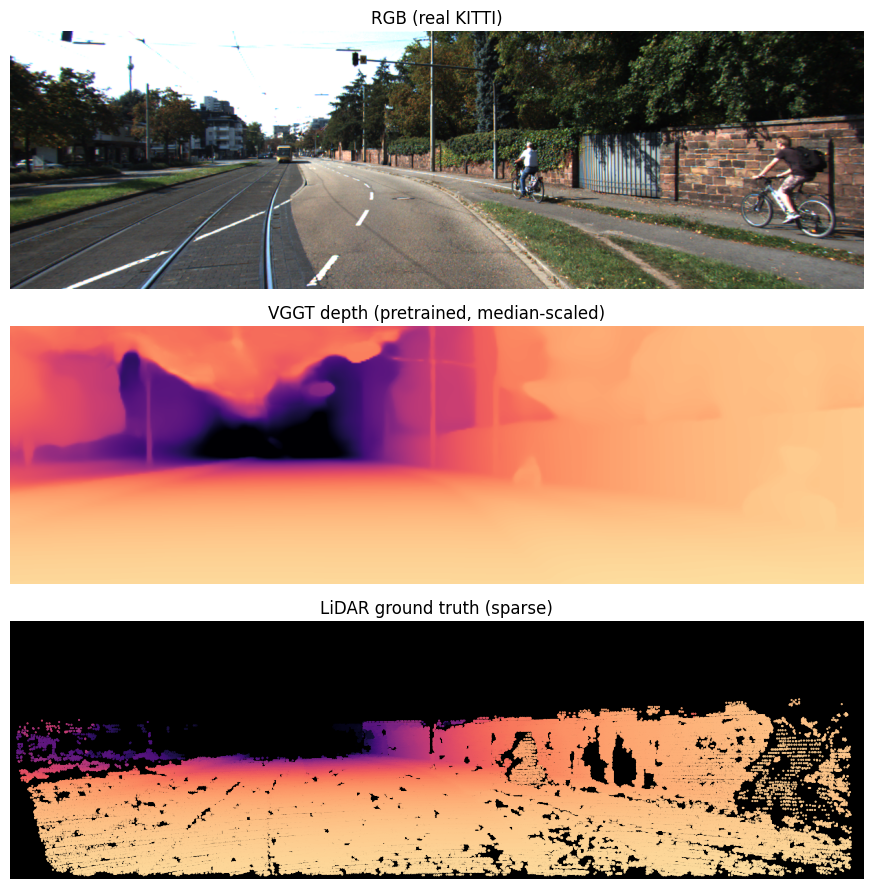

In [11]:
win = make_windows(kitti_by_drive[DRIVES[0]], N_VIEWS)[0]
depth, conf = predict_depth(model, [r for r, _ in win], device, dtype, load_and_preprocess_images)
rgb_path, gt_path = win[0]
gt = read_kitti_depth(gt_path)
pred = upsample_to(depth[0], *gt.shape)
show(compute_metrics(pred, gt, use_garg_crop=True))

valid = gt > 0
pred_scaled = pred * np.median(gt[valid]) / np.median(pred[valid])
ys, xs = np.nonzero(valid)
fig, ax = plt.subplots(3, 1, figsize=(12, 9))
ax[0].imshow(Image.open(rgb_path)); ax[0].set_title('RGB (real KITTI)')
ax[1].imshow(np.clip(pred_scaled, 0, 80), cmap='magma_r', vmin=0, vmax=80); ax[1].set_title('VGGT depth (pretrained, median-scaled)')
ax[2].imshow(np.zeros_like(gt), cmap='gray', vmin=0, vmax=1)
ax[2].scatter(xs, ys, c=gt[valid], s=0.3, cmap='magma_r', vmin=0, vmax=80); ax[2].set_title('LiDAR ground truth (sparse)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/kitti_baseline_example.png', dpi=150); plt.show()

### E2. Baseline on Virtual KITTI Scene02 and real KITTI

In [12]:
res_vk_base    = run_eval(model, 'vkitti', 'baseline_w518', LOADERS[518]);  show(res_vk_base)
res_kitti_base = run_eval(model, 'kitti',  'baseline_w518', LOADERS[518]);  show(res_kitti_base)

{'abs_rel': 0.0384, 'sq_rel': 0.4814, 'rmse': 4.1449, 'rmse_log': 0.1055, 'd1': 0.9743, 'd2': 0.9851, 'd3': 0.9924, 'n_frames': 160, 'n_views': 8, 'dataset': 'vkitti', 'model': 'baseline_w518'}
{'abs_rel': 0.0489, 'sq_rel': 0.2327, 'rmse': 2.9316, 'rmse_log': 0.0861, 'd1': 0.9695, 'd2': 0.9933, 'd3': 0.9974, 'n_frames': 192, 'n_views': 8, 'dataset': 'kitti', 'model': 'baseline_w518'}


### E3. Free the GPU

In [13]:
free_gpu()

GPU memory still allocated in the notebook: 0.17 GB


# Part F — Training and selection tools (run every session before G, I or K)

Both experiments use the same procedure, defined once here:

1. **Train and save every epoch.** 30 epochs of 100 steps (3,000 steps). In VGGT's code, an epoch is a fixed number of steps, not a full pass over the data.
2. **Choose the epoch with early stopping** on the validation drives: keep the best epoch so far, and stop after 5 epochs without improvement.
3. **Test once:** the selected depth head and the last one. The test drives are never used for the choice.

### F1. Settings and training configuration

Sets the training length, the patience and the learning rate, and writes VGGT's training config as a template. Only the depth head is trained (the aggregator is frozen), on the 4 Virtual KITTI training scenes, starting from the pretrained weights saved in Part E. The values that change between runs are placeholders: width, epochs, steps, learning rate and folders.

### F2. Training and selection functions

- `train(width, ...)` runs VGGT's training. A background job keeps only the depth head of each checkpoint on Drive and deletes the full 5 GB checkpoint, so the disk doesn't fill up.
- `train_losses(run)` plots the training losses per epoch.
- `select_epoch(run, width, ...)` evaluates all candidates on the validation drives and applies early stopping.
- `test_models(...)` tests the selected and the last depth head, and compares them frame by frame with the pretrained model.
- `test_curve(...)` is a check after the choice: validation curve vs test curve.
- `greedy_soup(...)` and `test_head(...)` are used for the averaging test in Part K.

The depth heads stay on Drive, so selection and testing can be repeated without training again.

In [8]:
EPOCHS, STEPS = 30, 100        # 30 epochs x 100 steps = 3,000 steps
PATIENCE = 5                   # early stopping: stop after 5 epochs without improvement
LR = '5e-5'                    # learning rate of the main runs (as text, written into the config)
MAX_IMG_PER_GPU = 8
IMG_NUMS = '[2, 8]'
AMP_DTYPE = 'bfloat16' if BF16_OK else 'float16'
assert AMP_DTYPE == 'bfloat16', 'training needs an A100 (or L4) runtime'
TRAIN_DIR = f'{REPO}/training'

CONFIG_TEMPLATE = '''defaults:
  - default_dataset.yaml

exp_name: __EXP__
img_size: __WIDTH__
num_workers: 2
seed_value: 42
accum_steps: 1
patch_size: 14
val_epoch_freq: 1
max_img_per_gpu: __MAXIMG__

limit_train_batches: __STEPS__
limit_val_batches: 20

data:
  train:
    _target_: data.dynamic_dataloader.DynamicTorchDataset
    num_workers: ${num_workers}
    max_img_per_gpu: ${max_img_per_gpu}
    common_config:
      img_size: ${img_size}
      patch_size: ${patch_size}
      debug: False
      repeat_batch: False
      img_nums: __IMGNUMS__
      augs:
        aspects: [0.28, 0.34]
    dataset:
      _target_: data.composed_dataset.ComposedDataset
      dataset_configs:
        - _target_: data.datasets.vkitti.VKittiDataset
          split: train
          VKitti_DIR: __TRAIN__
          len_train: 800
  val:
    _target_: data.dynamic_dataloader.DynamicTorchDataset
    num_workers: ${num_workers}
    max_img_per_gpu: ${max_img_per_gpu}
    common_config:
      img_size: ${img_size}
      patch_size: ${patch_size}
      debug: False
      img_nums: __IMGNUMS__
      augs:
        aspects: [0.30, 0.30]
    dataset:
      _target_: data.composed_dataset.ComposedDataset
      dataset_configs:
        - _target_: data.datasets.vkitti.VKittiDataset
          split: test
          VKitti_DIR: __VAL__
          len_test: 1

logging:
  log_dir: logs
  log_visuals: False
  log_freq: 10
  log_level_primary: INFO
  log_level_secondary: WARNING
  all_ranks: False
  tensorboard_writer:
    _target_: train_utils.tb_writer.TensorBoardLogger
    path: ${logging.log_dir}/tensorboard
  scalar_keys_to_log:
    train:
      keys_to_log: [loss_objective, loss_conf_depth, loss_reg_depth, loss_grad_depth]
    val:
      keys_to_log: [loss_objective, loss_conf_depth, loss_reg_depth, loss_grad_depth]

checkpoint:
  save_dir: __CKPTDIR__
  save_freq: 1
  resume_checkpoint_path: __PRETRAINED__
  strict: False

loss:
  _target_: loss.MultitaskLoss
  camera: null
  depth:
    weight: 1.0
    gradient_loss_fn: "grad"
    valid_range: 0.98
  point: null
  track: null

optim:
  param_group_modifiers: False
  optimizer:
    _target_: torch.optim.AdamW
    lr: __LR__
    weight_decay: 0.05
  frozen_module_names:
    - "*aggregator*"
  amp:
    enabled: True
    amp_dtype: __AMP__
  gradient_clip:
    _target_: train_utils.gradient_clip.GradientClipper
    configs:
      - module_name: ["depth"]
        max_norm: 1.0
        norm_type: 2
  options:
    lr:
      - scheduler:
          _target_: fvcore.common.param_scheduler.CompositeParamScheduler
          schedulers:
            - _target_: fvcore.common.param_scheduler.LinearParamScheduler
              start_value: 1e-8
              end_value: __LR__
            - _target_: fvcore.common.param_scheduler.CosineParamScheduler
              start_value: __LR__
              end_value: 1e-8
          lengths: [0.05, 0.95]
          interval_scaling: ['rescaled', 'rescaled']
    weight_decay:
      - scheduler:
          _target_: fvcore.common.param_scheduler.ConstantParamScheduler
          value: 0.05

max_epochs: __EPOCHS__

model:
  _target_: vggt.models.vggt.VGGT
  enable_camera: False
  enable_depth: True
  enable_point: False
  enable_track: False

distributed:
  backend: nccl
  comms_dtype: None
  find_unused_parameters: False
  timeout_mins: 30
  gradient_as_bucket_view: True
  bucket_cap_mb: 25
  broadcast_buffers: True

cuda:
  cudnn_deterministic: False
  cudnn_benchmark: False
  allow_tf32: True
'''
print(f'training length: {EPOCHS} epochs x {STEPS} steps = {EPOCHS * STEPS} steps | patience: {PATIENCE}')

training length: 30 epochs x 100 steps = 3000 steps | patience: 5


In [9]:
def run_name(width, epochs=EPOCHS, steps=STEPS, lr=LR):
    extra = '' if lr == '5e-5' else f'_lr{lr}'
    return f'vkitti4_depth_w{width}_{epochs}x{steps}{extra}'
head_dir = lambda run: f'{CKPT_DIR}/{run}_heads'
epoch_of = lambda p: int(re.search(r'(\d+)\.pt$', os.path.basename(p)).group(1))

def extract_head(ckpt_path, out_dir):
    """Keep only the depth head of a full checkpoint (small file on Drive), then delete the checkpoint."""
    sd = torch.load(ckpt_path, map_location='cpu'); sd = sd.get('model', sd)
    sd = {k.replace('module.', '', 1): v for k, v in sd.items()}
    head = {k[len('depth_head.'):]: v for k, v in sd.items() if k.startswith('depth_head.')}
    assert len(head) > 0, f'no depth_head weights in {ckpt_path}'
    torch.save(head, f'{out_dir}/depth_head_epoch{epoch_of(ckpt_path)}.pt')
    del sd
    os.remove(ckpt_path)

def load_heads(run):
    return {epoch_of(p): p for p in glob.glob(f'{head_dir(run)}/depth_head_epoch*.pt')}

# ---------- 1. training ----------
def train(width, epochs=EPOCHS, steps=STEPS, lr=LR):
    run = run_name(width, epochs, steps, lr)
    local = f'/content/ckpt_{run}'
    assert os.path.exists(PRETRAINED_CKPT), 'run the first cell of Part E once'
    free_gpu()
    shutil.rmtree(local, ignore_errors=True)                  # never continue an old run
    shutil.rmtree(head_dir(run), ignore_errors=True); os.makedirs(head_dir(run))

    cfg = CONFIG_TEMPLATE
    for k, v in {'__EXP__': run, '__WIDTH__': str(width), '__MAXIMG__': str(MAX_IMG_PER_GPU),
                 '__IMGNUMS__': IMG_NUMS, '__STEPS__': str(steps), '__EPOCHS__': str(epochs),
                 '__LR__': lr, '__TRAIN__': VKITTI_TRAIN, '__VAL__': VKITTI_VAL, '__AMP__': AMP_DTYPE,
                 '__CKPTDIR__': local, '__PRETRAINED__': PRETRAINED_CKPT}.items():
        cfg = cfg.replace(k, v)
    assert '__' not in cfg.replace('__init__', ''), 'a placeholder was not replaced'
    open(f'{TRAIN_DIR}/config/{run}.yaml', 'w').write(cfg)
    for p in [f'{VKITTI_TRAIN}/sequence_list.txt', f'{VKITTI_VAL}/sequence_list.txt']:
        if os.path.exists(p): os.remove(p)                    # stale cache of the VGGT data loader
    free_gb = shutil.disk_usage('/content').free / 1e9
    assert free_gb > 20, f'only {free_gb:.0f} GB free on the local disk'

    stop = threading.Event()
    def watcher():
        while not stop.is_set():
            ckpts = sorted(glob.glob(f'{local}/checkpoint_*.pt'), key=epoch_of)
            for p in ckpts[:-1]:                              # the newest may still be written
                try: extract_head(p, head_dir(run))
                except Exception as err: print('watcher:', err)
            stop.wait(20)
    job = threading.Thread(target=watcher, daemon=True); job.start()

    log = f'{LOG_DIR}/{run}_train.log'
    print(f'training {run} ({epochs} epochs x {steps} steps, width {width}, lr {lr})')
    get_ipython().system(f'cd {TRAIN_DIR} && PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True '
                         f'torchrun --nproc_per_node=1 launch.py --config {run} 2>&1 | tee {log} | '
                         f'grep -E "Train Epoch.*\\[ *{steps}/|Error|error|issing" | tail -n 80')
    stop.set(); job.join()
    for p in sorted(glob.glob(f'{local}/checkpoint_*.pt'), key=epoch_of):
        extract_head(p, head_dir(run))
    shutil.rmtree(local, ignore_errors=True)
    heads = load_heads(run)
    print('depth heads saved for epochs:', sorted(heads))
    assert len(heads) == epochs, 'some epochs are missing - check the log on Drive'
    return run

def train_losses(run):
    """Average training losses of each epoch, read from the log."""
    last = {}
    for line in open(f'{LOG_DIR}/{run}_train.log').read().splitlines():
        m = re.search(r'Train Epoch: \[(\d+)\]', line)
        if m: last[int(m.group(1))] = line
    def avg(line, key):
        m = re.search(rf'{key}: [-\d.]+ \(([-\d.]+)\)', line)
        return float(m.group(1)) if m else np.nan
    keys = {'objective': 'total loss', 'reg_depth': 'depth error term', 'grad_depth': 'gradient term'}
    losses = {e: {k: avg(last[e], f'train_loss_{k}') for k in keys} for e in sorted(last)}
    json.dump(losses, open(f'{RESULTS_DIR}/{run}_train_losses.json', 'w'), indent=1)
    es = sorted(losses)
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
    for a, (k, name) in zip(ax, keys.items()):
        a.plot(es, [losses[e][k] for e in es], marker='o', ms=3)
        a.set_title(name); a.set_xlabel('epoch'); a.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/train_loss_{run}.png', dpi=150); plt.show()
    return losses

# ---------- 2. selection with early stopping ----------
def load_model():
    global model, pretrained_head
    model = VGGT.from_pretrained('facebook/VGGT-1B').to(device).eval()
    pretrained_head = {k: v.detach().clone() for k, v in model.depth_head.state_dict().items()}

def set_head(e, heads):
    """e = -1: pretrained depth head; otherwise the depth head saved after epoch e."""
    model.depth_head.load_state_dict(pretrained_head if e == -1 else torch.load(heads[e], map_location='cpu'))

def name_of(e):
    return 'pretrained' if e == -1 else f'epoch {e}'

def select_epoch(run, width, epochs=EPOCHS, patience=PATIENCE):
    heads = load_heads(run)
    assert len(heads) == epochs, f'{run}: found {len(heads)} depth heads, expected {epochs} - train first'
    val = {}
    for e in [-1] + sorted(heads):
        set_head(e, heads)
        val[e] = eval_drives(model, kitti_val_by_drive, LOADERS[width])
        print(f'{name_of(e):10s}  val AbsRel {val[e]["abs_rel"]:.4f} | δ<1.25 {val[e]["d1"]:.4f}')

    chosen, since_best, stop_at = -1, 0, None
    for e in sorted(heads):
        if val[e]['abs_rel'] < val[chosen]['abs_rel']:
            chosen, since_best = e, 0
        else:
            since_best += 1
        if since_best >= patience:
            stop_at = e; break
    overall = min(val, key=lambda e: val[e]['abs_rel'])
    print(f'\nearly stopping: stopped at {name_of(stop_at) if stop_at is not None else "the end (never triggered)"}'
          f' -> selected {name_of(chosen)}')
    print(f'best over all {epochs} epochs (for information only): {name_of(overall)}')

    if chosen != -1:
        h = torch.load(heads[chosen], map_location='cpu')
        changed = sum(not torch.equal(h[k], pretrained_head[k].cpu()) for k in pretrained_head)
        print(f'depth-head tensors different from the pretrained ones: {changed}/{len(pretrained_head)}')
        assert changed > 0, 'the selected depth head is identical to the pretrained one'

    json.dump({str(e): r for e, r in val.items()} |
              {'chosen': chosen, 'stop_at': stop_at, 'overall_best': overall, 'patience': patience},
              open(f'{RESULTS_DIR}/{run}_selection_val.json', 'w'), indent=1)
    es = sorted(val)
    plt.figure(figsize=(9, 3.5))
    plt.plot(es, [val[e]['abs_rel'] for e in es], marker='o', ms=3)
    plt.axhline(val[-1]['abs_rel'], ls='--', c='gray', label='pretrained')
    plt.axvline(chosen, c='red', alpha=.5, label=f'selected ({name_of(chosen)})')
    if stop_at is not None:
        plt.axvline(stop_at, c='black', ls=':', label=f'early stop ({name_of(stop_at)})')
    plt.xlabel('epoch (-1 = pretrained)'); plt.ylabel('AbsRel, validation drives')
    plt.title(f'Epoch selection: {run}'); plt.grid(alpha=.3); plt.legend()
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/selection_{run}.png', dpi=150); plt.show()
    return heads, val, chosen

# ---------- 3. test once ----------
def test_models(run, width, heads, chosen, suffix=''):
    base, last = f'baseline_w{width}', max(heads)
    for kind, e in [('selected', chosen), ('last', last)]:
        tag = f'{kind}_w{width}{suffix}'
        set_head(e, heads)
        print(f'--- {tag}: {name_of(e)}')
        for ds in ['kitti', 'vkitti']:
            show(run_eval(model, ds, tag, LOADERS[width]))
        for ds in ['kitti', 'vkitti']:
            paired(ds, tag, base)

def test_curve(run, width, heads, val):
    """Check only, after the choice: does the validation curve predict the test curve?"""
    test = {}
    for e in [-1] + sorted(heads):
        set_head(e, heads)
        test[e] = eval_drives(model, kitti_by_drive, LOADERS[width])
        print(f'{name_of(e):10s}  val {val[e]["abs_rel"]:.4f} | test {test[e]["abs_rel"]:.4f}')
    es = sorted(test)
    corr = np.corrcoef([val[e]['abs_rel'] for e in es], [test[e]['abs_rel'] for e in es])[0, 1]
    print(f'correlation between validation and test AbsRel: {corr:.2f}')
    json.dump({str(e): r for e, r in test.items()} | {'correlation': corr},
              open(f'{RESULTS_DIR}/{run}_selection_test.json', 'w'), indent=1)
    plt.figure(figsize=(9, 3.5))
    plt.plot(es, [val[e]['abs_rel'] for e in es], marker='o', ms=3, label='validation drives')
    plt.plot(es, [test[e]['abs_rel'] for e in es], marker='s', ms=3, label='test drives')
    plt.xlabel('epoch (-1 = pretrained)'); plt.ylabel('AbsRel, real KITTI')
    plt.title(f'Validation vs test at width {width} (correlation {corr:.2f})'); plt.grid(alpha=.3); plt.legend()
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/val_vs_test_{run}.png', dpi=150); plt.show()
    return test

# ---------- extras for Part K ----------
def load_val(run):
    """Validation results saved by select_epoch (works in a new session)."""
    d = json.load(open(f'{RESULTS_DIR}/{run}_selection_val.json'))
    return {int(k): v for k, v in d.items() if k.lstrip('-').isdigit()}, d['chosen']

def average_heads(paths):
    """Average the weights of several depth heads of the same run."""
    hs = [torch.load(p, map_location='cpu') for p in paths]
    return {k: (sum(h[k].float() for h in hs) / len(hs)).to(hs[0][k].dtype)
               if hs[0][k].is_floating_point() else hs[0][k] for k in hs[0]}

def greedy_soup(run, width, heads, val, n_candidates=10):
    """Start from the best epoch; add the next best ones only if the validation AbsRel improves."""
    order = sorted(heads, key=lambda e: val[e]['abs_rel'])[:n_candidates]
    soup, best = [order[0]], val[order[0]]['abs_rel']
    print(f'start with {name_of(order[0])}: val AbsRel {best:.4f}')
    for e in order[1:]:
        model.depth_head.load_state_dict(average_heads([heads[x] for x in soup + [e]]))
        r = eval_drives(model, kitti_val_by_drive, LOADERS[width])['abs_rel']
        print(f'  + {name_of(e):9s} -> val AbsRel {r:.4f}  {"kept" if r < best else "rejected"}')
        if r < best:
            soup.append(e); best = r
    sd = average_heads([heads[x] for x in soup])
    path = f'{head_dir(run)}/depth_head_soup.pt'
    torch.save(sd, path)
    model.depth_head.load_state_dict(sd)
    res = eval_drives(model, kitti_val_by_drive, LOADERS[width])
    json.dump(res | {'epochs': sorted(soup)}, open(f'{RESULTS_DIR}/{run}_soup_val.json', 'w'), indent=1)
    print(f'averaged epochs {sorted(soup)}: val AbsRel {res["abs_rel"]:.4f} | δ<1.25 {res["d1"]:.4f}')
    return path, res

def test_head(state, width, tag):
    """Test any depth head (for example an averaged one) on both test sets."""
    model.depth_head.load_state_dict(state)
    for ds in ['kitti', 'vkitti']:
        show(run_eval(model, ds, tag, LOADERS[width]))
    for ds in ['kitti', 'vkitti']:
        paired(ds, tag, f'baseline_w{width}')

# Part G — Experiment 1: fine-tuning at width 518

**Run first:** A → C → D → F (and Part E once before).

**G1. Train** (about 30 minutes). Check that the "missing keys" are only camera, point and track-head keys, not depth-head keys. If the training is already done, skip G1: the depth heads are on Drive.

**G2. Choose the epoch** with early stopping on the validation drives (31 candidates: the pretrained head and 30 epochs).

**G3. Test once** the selected and the last depth head on both test sets, compared frame by frame with the pretrained model.

**G4. Check (after the choice):** validation curve vs test curve.

### G1. Train

GPU memory still allocated in the notebook: 0.17 GB
training vkitti4_depth_w518_30x100 (30 epochs x 100 steps, width 518)
/usr/local/lib/python3.13/dist-packages/hydra/_internal/defaults_list.py:251: UserWarning: In 'vkitti4_depth_w518_30x100': Defaults list is missing `_self_`. See https://hydra.cc/docs/1.2/upgrades/1.0_to_1.1/default_composition_order for more information
I0000 00:00:1792775011.298030    4347 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792775013.740397    4347 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
INFO 2026-10-23 17:05:37,345 trainer.py: 211: Model state loa

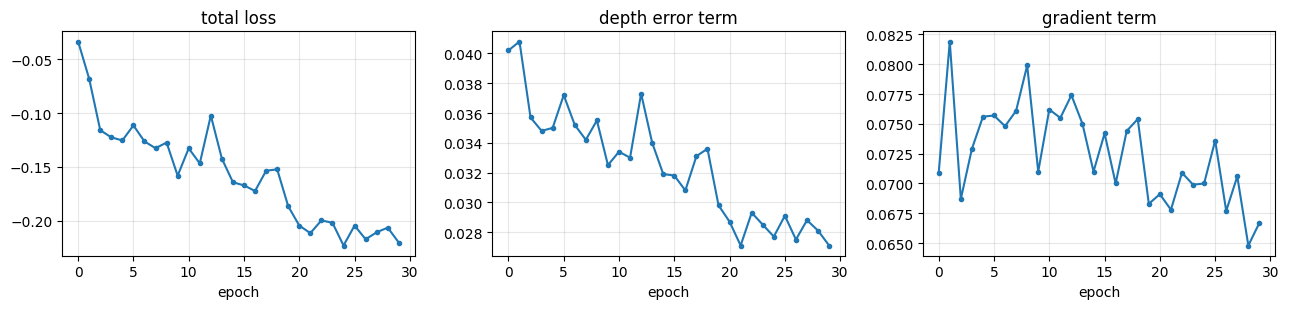

In [16]:
run518 = train(518)
losses518 = train_losses(run518)

### G2. Choose the epoch with early stopping

pretrained  val AbsRel 0.0739 | δ<1.25 0.9279
epoch 0     val AbsRel 0.0720 | δ<1.25 0.9277
epoch 1     val AbsRel 0.0822 | δ<1.25 0.9246
epoch 2     val AbsRel 0.0774 | δ<1.25 0.9274
epoch 3     val AbsRel 0.0724 | δ<1.25 0.9280
epoch 4     val AbsRel 0.0742 | δ<1.25 0.9315
epoch 5     val AbsRel 0.0701 | δ<1.25 0.9302
epoch 6     val AbsRel 0.0771 | δ<1.25 0.9268
epoch 7     val AbsRel 0.0719 | δ<1.25 0.9273
epoch 8     val AbsRel 0.0721 | δ<1.25 0.9274
epoch 9     val AbsRel 0.0707 | δ<1.25 0.9292
epoch 10    val AbsRel 0.0764 | δ<1.25 0.9241
epoch 11    val AbsRel 0.0719 | δ<1.25 0.9312
epoch 12    val AbsRel 0.0718 | δ<1.25 0.9288
epoch 13    val AbsRel 0.0715 | δ<1.25 0.9291
epoch 14    val AbsRel 0.0745 | δ<1.25 0.9267
epoch 15    val AbsRel 0.0739 | δ<1.25 0.9255
epoch 16    val AbsRel 0.0723 | δ<1.25 0.9281
epoch 17    val AbsRel 0.0715 | δ<1.25 0.9283
epoch 18    val AbsRel 0.0743 | δ<1.25 0.9250
epoch 19    val AbsRel 0.0757 | δ<1.25 0.9242
epoch 20    val AbsRel 0.0744 | δ<

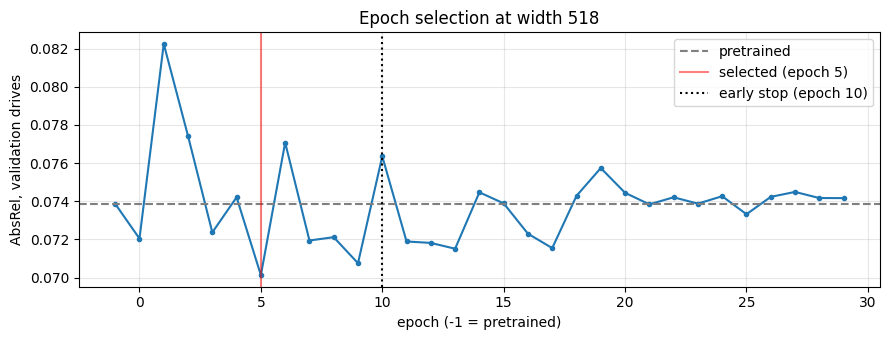

In [17]:
run518 = run_name(518)
load_model()
heads518, val518, chosen518 = select_epoch(run518, 518)

### G3. Test the selected and the last epoch

In [18]:
test_models(run518, 518, heads518, chosen518)

--- selected_w518: epoch 5
{'abs_rel': 0.0453, 'sq_rel': 0.2299, 'rmse': 2.8974, 'rmse_log': 0.0841, 'd1': 0.971, 'd2': 0.9926, 'd3': 0.9968, 'n_frames': 192, 'n_views': 8, 'dataset': 'kitti', 'model': 'selected_w518'}
{'abs_rel': 0.0404, 'sq_rel': 0.4633, 'rmse': 4.2026, 'rmse_log': 0.11, 'd1': 0.974, 'd2': 0.9843, 'd3': 0.9923, 'n_frames': 160, 'n_views': 8, 'dataset': 'vkitti', 'model': 'selected_w518'}
selected_w518 vs baseline_w518 / kitti : 192 frames | mean AbsRel change -0.0037 ± 0.0039 | better on 80% of frames
   2011_09_26_drive_0002: change -0.0055 | better on 100%
   2011_09_26_drive_0005: change +0.0007 | better on 39%
   2011_09_26_drive_0013: change -0.0062 | better on 100%
selected_w518 vs baseline_w518 / vkitti: 160 frames | mean AbsRel change +0.0020 ± 0.0026 | better on 18% of frames
--- last_w518: epoch 29
{'abs_rel': 0.0481, 'sq_rel': 0.2446, 'rmse': 3.0167, 'rmse_log': 0.087, 'd1': 0.968, 'd2': 0.9925, 'd3': 0.9969, 'n_frames': 192, 'n_views': 8, 'dataset': 'kitt

### G4. Check: validation curve vs test curve

pretrained  val 0.0739 | test 0.0489
epoch 0     val 0.0720 | test 0.0470
epoch 1     val 0.0822 | test 0.0604
epoch 2     val 0.0774 | test 0.0527
epoch 3     val 0.0724 | test 0.0482
epoch 4     val 0.0742 | test 0.0509
epoch 5     val 0.0701 | test 0.0453
epoch 6     val 0.0771 | test 0.0537
epoch 7     val 0.0719 | test 0.0475
epoch 8     val 0.0721 | test 0.0471
epoch 9     val 0.0707 | test 0.0463
epoch 10    val 0.0764 | test 0.0506
epoch 11    val 0.0719 | test 0.0471
epoch 12    val 0.0718 | test 0.0470
epoch 13    val 0.0715 | test 0.0476
epoch 14    val 0.0745 | test 0.0492
epoch 15    val 0.0739 | test 0.0485
epoch 16    val 0.0723 | test 0.0471
epoch 17    val 0.0715 | test 0.0460
epoch 18    val 0.0743 | test 0.0487
epoch 19    val 0.0757 | test 0.0501
epoch 20    val 0.0744 | test 0.0485
epoch 21    val 0.0738 | test 0.0481
epoch 22    val 0.0742 | test 0.0482
epoch 23    val 0.0739 | test 0.0476
epoch 24    val 0.0743 | test 0.0482
epoch 25    val 0.0733 | test 0.0473
e

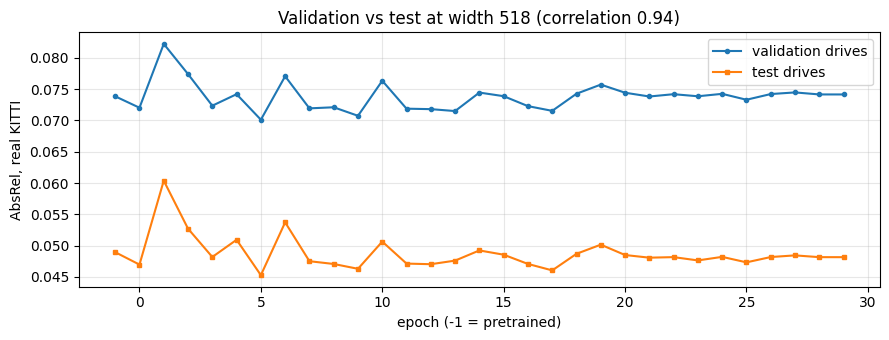

In [19]:
test518 = test_curve(run518, 518, heads518, val518)

# Part H — View-count ablation (selected model of Experiment 1)

We evaluate the pretrained model and the selected model of Experiment 1 on the same 192 real-KITTI test frames with windows of 2, 4, 8 and 16 frames. Only the number of frames that the model sees together changes. This part needs no training, but it needs the model and the selection from G2 in the same session.

**H1** runs the evaluations (about 10 minutes) and prints the AbsRel for every setting.

**H2** draws AbsRel and δ<1.25 against the number of views, and saves the figure `view_ablation_kitti.png` for the report.

### H1. Run the ablation

In [20]:
VIEWS = [2, 4, 8, 16]
ablation = {}
for kind, e, tag in [('pretrained', -1, 'baseline_w518'), ('selected', chosen518, 'selected_w518')]:
    set_head(e, heads518)
    ablation[kind] = {n: run_eval(model, 'kitti', tag, LOADERS[518], n_views=n) for n in VIEWS}

print('views | pretrained | selected | difference')
for n in VIEWS:
    p, s = ablation['pretrained'][n]['abs_rel'], ablation['selected'][n]['abs_rel']
    print(f'{n:5d} | {p:10.4f} | {s:8.4f} | {s - p:+.4f} ({(s - p) / p:+.1%})')

views | pretrained | selected | difference
    2 |     0.0587 |   0.0539 | -0.0048 (-8.2%)
    4 |     0.0541 |   0.0498 | -0.0043 (-8.0%)
    8 |     0.0489 |   0.0453 | -0.0037 (-7.5%)
   16 |     0.0450 |   0.0422 | -0.0029 (-6.3%)


### H2. Plot

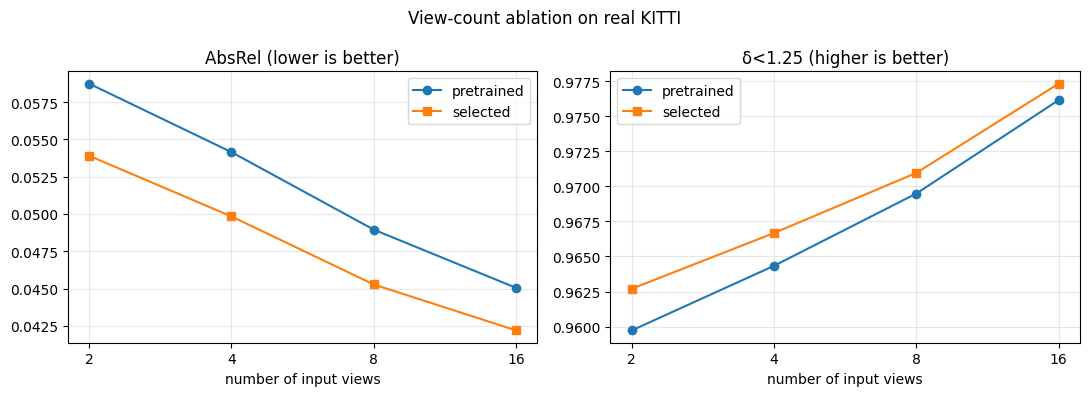

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for kind, marker in [('pretrained', 'o'), ('selected', 's')]:
    ax[0].plot(VIEWS, [ablation[kind][n]['abs_rel'] for n in VIEWS], marker=marker, label=kind)
    ax[1].plot(VIEWS, [ablation[kind][n]['d1'] for n in VIEWS], marker=marker, label=kind)
for a, t in zip(ax, ['AbsRel (lower is better)', 'δ<1.25 (higher is better)']):
    a.set_xscale('log', base=2); a.set_xticks(VIEWS); a.set_xticklabels(VIEWS)
    a.set_xlabel('number of input views'); a.set_title(t); a.grid(alpha=.3); a.legend()
plt.suptitle('View-count ablation on real KITTI'); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/view_ablation_kitti.png', dpi=150); plt.show()

# Part I — Experiment 2: fine-tuning at width 336

Same procedure as Experiment 1, with images 336 pixels wide instead of 518 (168 tokens per image instead of 407).

**Run first:** A → C → D → F (and Part E once before).

**I1. Train at width 336.** Skip it if the training is already done.

**I2. Baseline and epoch choice.** Evaluates the pretrained model at width 336 (tag `baseline_w336`), then chooses the epoch with early stopping.

**I3. Test once** the selected and the last depth head, compared frame by frame with the pretrained model at width 336.

**I4. Check (after the choice):** validation curve vs test curve.

**I5. Compare the two widths:** validation curves of both experiments, relative to their own pretrained model. Saved as `selection_both_widths.png`.

### I1. Train at width 336

GPU memory still allocated in the notebook: 0.17 GB
training vkitti4_depth_w336_30x100 (30 epochs x 100 steps, width 336)
/usr/local/lib/python3.13/dist-packages/hydra/_internal/defaults_list.py:251: UserWarning: In 'vkitti4_depth_w336_30x100': Defaults list is missing `_self_`. See https://hydra.cc/docs/1.2/upgrades/1.0_to_1.1/default_composition_order for more information
I0000 00:00:1792779029.243390   22920 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792779032.125601   22920 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
INFO 2026-10-23 18:11:10,028 trainer.py: 211: Model state loa

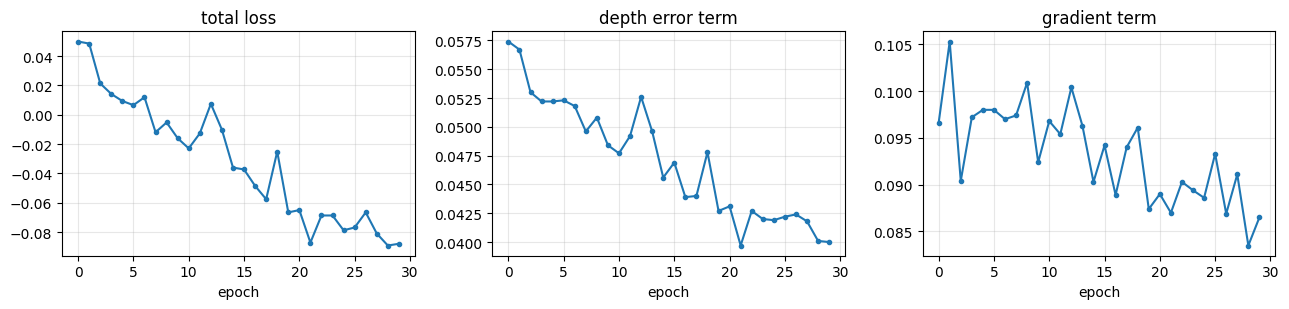

In [22]:
run336 = train(336)
losses336 = train_losses(run336)

### I2. Baseline at width 336, then choose the epoch

{'abs_rel': 0.0897, 'sq_rel': 0.5234, 'rmse': 4.4762, 'rmse_log': 0.1394, 'd1': 0.9145, 'd2': 0.9813, 'd3': 0.9935, 'n_frames': 192, 'n_views': 8, 'dataset': 'kitti', 'model': 'baseline_w336'}
{'abs_rel': 0.0784, 'sq_rel': 1.0022, 'rmse': 6.0222, 'rmse_log': 0.1557, 'd1': 0.948, 'd2': 0.9767, 'd3': 0.9859, 'n_frames': 160, 'n_views': 8, 'dataset': 'vkitti', 'model': 'baseline_w336'}
pretrained  val AbsRel 0.1051 | δ<1.25 0.8809
epoch 0     val AbsRel 0.0906 | δ<1.25 0.9043
epoch 1     val AbsRel 0.0937 | δ<1.25 0.9001
epoch 2     val AbsRel 0.0875 | δ<1.25 0.9084
epoch 3     val AbsRel 0.0910 | δ<1.25 0.9127
epoch 4     val AbsRel 0.0924 | δ<1.25 0.9087
epoch 5     val AbsRel 0.0827 | δ<1.25 0.9161
epoch 6     val AbsRel 0.0857 | δ<1.25 0.9153
epoch 7     val AbsRel 0.0862 | δ<1.25 0.9123
epoch 8     val AbsRel 0.0929 | δ<1.25 0.8969
epoch 9     val AbsRel 0.0825 | δ<1.25 0.9143
epoch 10    val AbsRel 0.0822 | δ<1.25 0.9181
epoch 11    val AbsRel 0.0878 | δ<1.25 0.9127
epoch 12    val 

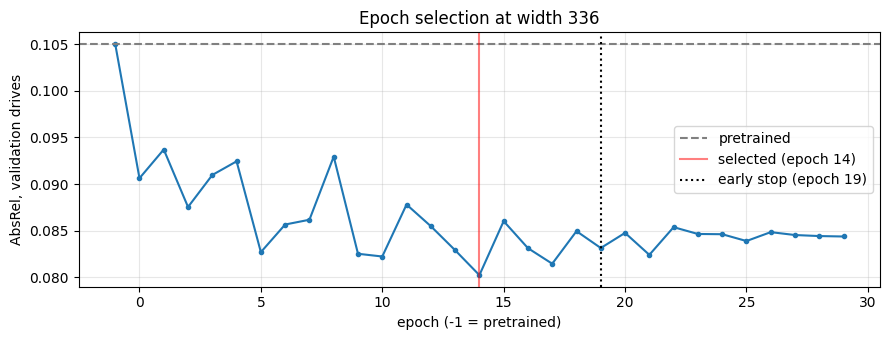

In [23]:
run336 = run_name(336)
load_model()
res_kitti_base336 = run_eval(model, 'kitti',  'baseline_w336', LOADERS[336]);  show(res_kitti_base336)
res_vk_base336    = run_eval(model, 'vkitti', 'baseline_w336', LOADERS[336]);  show(res_vk_base336)
heads336, val336, chosen336 = select_epoch(run336, 336)

### I3. Test the selected and the last epoch

In [24]:
test_models(run336, 336, heads336, chosen336)

--- selected_w336: epoch 14
{'abs_rel': 0.0675, 'sq_rel': 0.3942, 'rmse': 3.7707, 'rmse_log': 0.113, 'd1': 0.9467, 'd2': 0.9861, 'd3': 0.9945, 'n_frames': 192, 'n_views': 8, 'dataset': 'kitti', 'model': 'selected_w336'}
{'abs_rel': 0.0623, 'sq_rel': 0.7756, 'rmse': 5.1678, 'rmse_log': 0.1373, 'd1': 0.9575, 'd2': 0.9786, 'd3': 0.9899, 'n_frames': 160, 'n_views': 8, 'dataset': 'vkitti', 'model': 'selected_w336'}
selected_w336 vs baseline_w336 / kitti : 192 frames | mean AbsRel change -0.0222 ± 0.0098 | better on 96% of frames
   2011_09_26_drive_0002: change -0.0231 | better on 100%
   2011_09_26_drive_0005: change -0.0159 | better on 89%
   2011_09_26_drive_0013: change -0.0277 | better on 100%
selected_w336 vs baseline_w336 / vkitti: 160 frames | mean AbsRel change -0.0160 ± 0.0099 | better on 95% of frames
--- last_w336: epoch 29
{'abs_rel': 0.0692, 'sq_rel': 0.4103, 'rmse': 3.9124, 'rmse_log': 0.1167, 'd1': 0.9425, 'd2': 0.9855, 'd3': 0.9945, 'n_frames': 192, 'n_views': 8, 'dataset':

### I4. Check: validation curve vs test curve

pretrained  val 0.1051 | test 0.0897
epoch 0     val 0.0906 | test 0.0759
epoch 1     val 0.0937 | test 0.0789
epoch 2     val 0.0875 | test 0.0732
epoch 3     val 0.0910 | test 0.0785
epoch 4     val 0.0924 | test 0.0793
epoch 5     val 0.0827 | test 0.0687
epoch 6     val 0.0857 | test 0.0741
epoch 7     val 0.0862 | test 0.0737
epoch 8     val 0.0929 | test 0.0751
epoch 9     val 0.0825 | test 0.0666
epoch 10    val 0.0822 | test 0.0692
epoch 11    val 0.0878 | test 0.0736
epoch 12    val 0.0855 | test 0.0716
epoch 13    val 0.0829 | test 0.0686
epoch 14    val 0.0802 | test 0.0675
epoch 15    val 0.0860 | test 0.0714
epoch 16    val 0.0831 | test 0.0701
epoch 17    val 0.0814 | test 0.0660
epoch 18    val 0.0849 | test 0.0700
epoch 19    val 0.0831 | test 0.0686
epoch 20    val 0.0848 | test 0.0689
epoch 21    val 0.0824 | test 0.0666
epoch 22    val 0.0854 | test 0.0701
epoch 23    val 0.0846 | test 0.0690
epoch 24    val 0.0846 | test 0.0694
epoch 25    val 0.0839 | test 0.0687
e

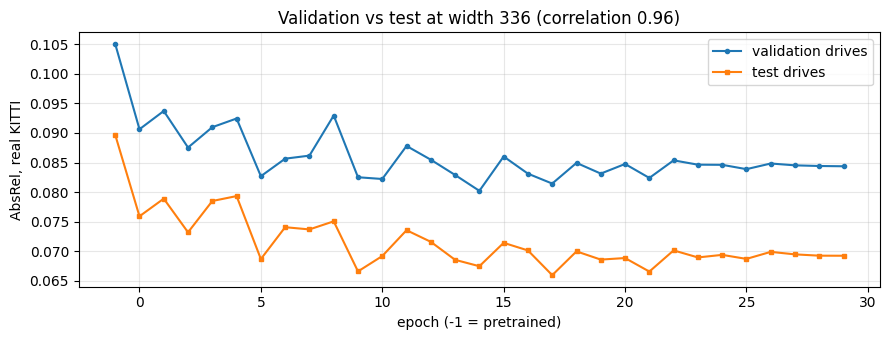

In [27]:
test336 = test_curve(run336, 336, heads336, val336)

   ### I5. Compare the two widths

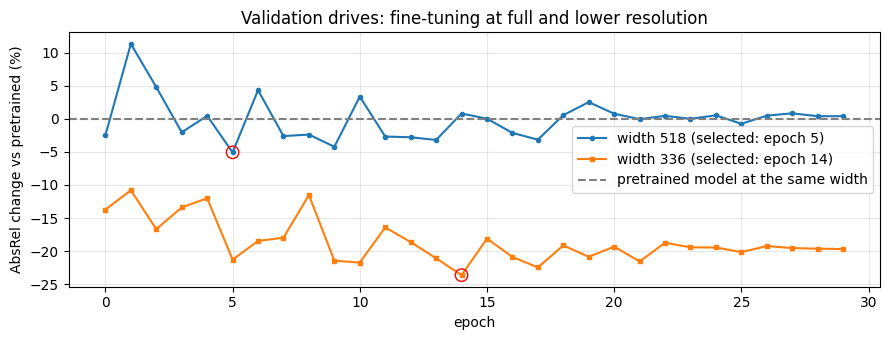

In [29]:
plt.figure(figsize=(9, 3.5))
for width, marker in [(518, 'o'), (336, 's')]:
    sel = json.load(open(f'{RESULTS_DIR}/{run_name(width)}_selection_val.json'))
    base = sel['-1']['abs_rel']
    es = list(range(EPOCHS))
    change = [100 * (sel[str(e)]['abs_rel'] - base) / base for e in es]
    plt.plot(es, change, marker=marker, ms=3, label=f'width {width} (selected: epoch {sel["chosen"]})')
    plt.scatter([sel['chosen']], [change[sel['chosen']]], s=80, facecolors='none', edgecolors='red', zorder=3)
plt.axhline(0, ls='--', c='gray', label='pretrained model at the same width')
plt.xlabel('epoch'); plt.ylabel('AbsRel change vs pretrained (%)')
plt.title('Validation drives: fine-tuning at full and lower resolution')
plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/selection_both_widths.png', dpi=150); plt.show()

# Part K — Three improvements, tested one at a time (width 518)

Each test changes **one thing** compared with the main run of Experiment 1 (30 × 100 steps, learning rate 5e-5):

- **K1. Averaging:** no new training. Starting from the best epoch on validation, we average it with the next best epochs, one by one, and keep an epoch only if the validation AbsRel improves (a "greedy soup").
- **K2. Saving more often:** the same 3,000 steps, but saved every 50 steps (60 epochs × 50 steps). The patience is 10 epochs, the same 500 steps as before.
- **K3. Smaller learning rate:** the same 30 × 100 steps with a learning rate of 1e-5.

All choices are made on the **validation drives**. Each variant is tested only once, in K5. K2 and K3 are new training runs, so part of a small difference can come from the randomness of training.

**Before this part, run:** A → C → D → F.

### K1. Averaging

In [10]:
run518 = run_name(518)
load_model()
heads518 = load_heads(run518)
val518, chosen518 = load_val(run518)
soup_path, soup_val = greedy_soup(run518, 518, heads518, val518)

config.json:   0%|          | 0.00/62.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 5.03GB            

model.safetensors: downloading bytes:           |  0.00B            

start with epoch 5: val AbsRel 0.0701
  + epoch 9   -> val AbsRel 0.0705  rejected
  + epoch 13  -> val AbsRel 0.0706  rejected
  + epoch 17  -> val AbsRel 0.0706  rejected
  + epoch 12  -> val AbsRel 0.0709  rejected
  + epoch 11  -> val AbsRel 0.0706  rejected
  + epoch 7   -> val AbsRel 0.0709  rejected
  + epoch 0   -> val AbsRel 0.0711  rejected
  + epoch 8   -> val AbsRel 0.0710  rejected
  + epoch 16  -> val AbsRel 0.0710  rejected
averaged epochs [5]: val AbsRel 0.0701 | δ<1.25 0.9302


### K2. Saving more often

GPU memory still allocated in the notebook: 0.01 GB
training vkitti4_depth_w518_60x50 (60 epochs x 50 steps, width 518, lr 5e-5)
/usr/local/lib/python3.13/dist-packages/hydra/_internal/defaults_list.py:251: UserWarning: In 'vkitti4_depth_w518_60x50': Defaults list is missing `_self_`. See https://hydra.cc/docs/1.2/upgrades/1.0_to_1.1/default_composition_order for more information
I0000 00:00:1792829261.186358    3983 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792829263.663510    3983 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
INFO 2026-10-24 08:10:07,294 trainer.py: 211: Model sta

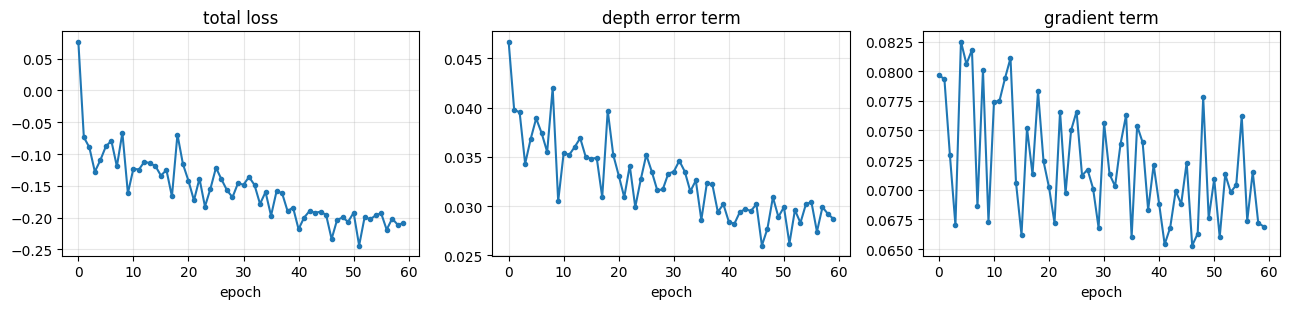

pretrained  val AbsRel 0.0739 | δ<1.25 0.9279
epoch 0     val AbsRel 0.0739 | δ<1.25 0.9308
epoch 1     val AbsRel 0.0789 | δ<1.25 0.9255
epoch 2     val AbsRel 0.0721 | δ<1.25 0.9292
epoch 3     val AbsRel 0.0729 | δ<1.25 0.9277
epoch 4     val AbsRel 0.0757 | δ<1.25 0.9231
epoch 5     val AbsRel 0.0695 | δ<1.25 0.9296
epoch 6     val AbsRel 0.0761 | δ<1.25 0.9256
epoch 7     val AbsRel 0.0755 | δ<1.25 0.9247
epoch 8     val AbsRel 0.0706 | δ<1.25 0.9325
epoch 9     val AbsRel 0.0762 | δ<1.25 0.9248
epoch 10    val AbsRel 0.0721 | δ<1.25 0.9301
epoch 11    val AbsRel 0.0756 | δ<1.25 0.9264
epoch 12    val AbsRel 0.0734 | δ<1.25 0.9330
epoch 13    val AbsRel 0.0792 | δ<1.25 0.9257
epoch 14    val AbsRel 0.0699 | δ<1.25 0.9336
epoch 15    val AbsRel 0.0707 | δ<1.25 0.9312
epoch 16    val AbsRel 0.0709 | δ<1.25 0.9288
epoch 17    val AbsRel 0.0736 | δ<1.25 0.9306
epoch 18    val AbsRel 0.0779 | δ<1.25 0.9219
epoch 19    val AbsRel 0.0713 | δ<1.25 0.9292
epoch 20    val AbsRel 0.0731 | δ<

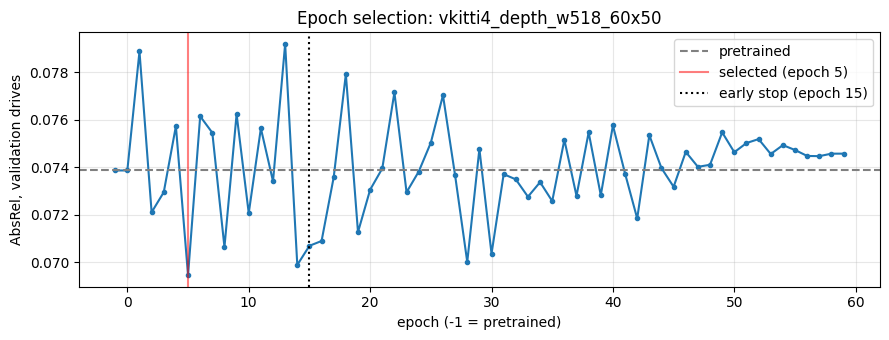

In [11]:
run50 = train(518, epochs=60, steps=50)
losses50 = train_losses(run50)
load_model()
heads50, val50, chosen50 = select_epoch(run50, 518, epochs=60, patience=10)

### K3. Smaller learning rate

GPU memory still allocated in the notebook: 0.01 GB
training vkitti4_depth_w518_30x100_lr1e-5 (30 epochs x 100 steps, width 518, lr 1e-5)
/usr/local/lib/python3.13/dist-packages/hydra/_internal/defaults_list.py:251: UserWarning: In 'vkitti4_depth_w518_30x100_lr1e-5': Defaults list is missing `_self_`. See https://hydra.cc/docs/1.2/upgrades/1.0_to_1.1/default_composition_order for more information
I0000 00:00:1792832359.484985   20048 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792832362.510646   20048 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
INFO 2026-10-24 09:00:07,033 trainer.p

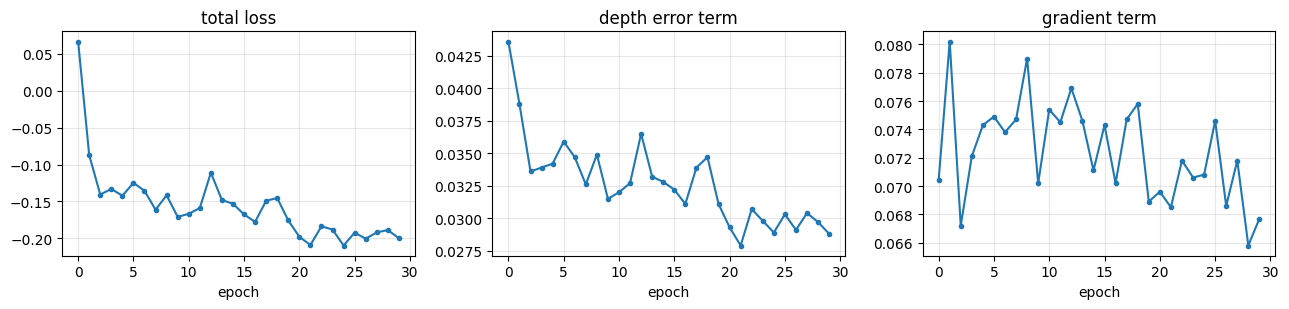

pretrained  val AbsRel 0.0739 | δ<1.25 0.9279
epoch 0     val AbsRel 0.0755 | δ<1.25 0.9280
epoch 1     val AbsRel 0.0766 | δ<1.25 0.9257
epoch 2     val AbsRel 0.0757 | δ<1.25 0.9275
epoch 3     val AbsRel 0.0751 | δ<1.25 0.9259
epoch 4     val AbsRel 0.0755 | δ<1.25 0.9263
epoch 5     val AbsRel 0.0757 | δ<1.25 0.9254
epoch 6     val AbsRel 0.0740 | δ<1.25 0.9264
epoch 7     val AbsRel 0.0747 | δ<1.25 0.9245
epoch 8     val AbsRel 0.0764 | δ<1.25 0.9259
epoch 9     val AbsRel 0.0752 | δ<1.25 0.9260
epoch 10    val AbsRel 0.0766 | δ<1.25 0.9239
epoch 11    val AbsRel 0.0741 | δ<1.25 0.9279
epoch 12    val AbsRel 0.0748 | δ<1.25 0.9264
epoch 13    val AbsRel 0.0755 | δ<1.25 0.9251
epoch 14    val AbsRel 0.0742 | δ<1.25 0.9270
epoch 15    val AbsRel 0.0758 | δ<1.25 0.9237
epoch 16    val AbsRel 0.0751 | δ<1.25 0.9258
epoch 17    val AbsRel 0.0779 | δ<1.25 0.9228
epoch 18    val AbsRel 0.0771 | δ<1.25 0.9224
epoch 19    val AbsRel 0.0776 | δ<1.25 0.9223
epoch 20    val AbsRel 0.0775 | δ<

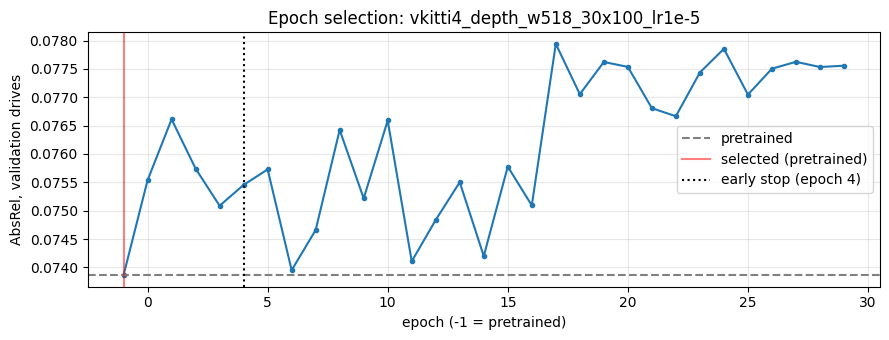

In [12]:
runlr = train(518, lr='1e-5')
losseslr = train_losses(runlr)
load_model()
headslr, vallr, chosenlr = select_epoch(runlr, 518)

### K4. Comparison on the validation drives

In [13]:
rows = {}
v, c = load_val(run_name(518));                   rows['main run (selected)']   = v[c]
rows['main run, averaged heads'] = json.load(open(f'{RESULTS_DIR}/{run_name(518)}_soup_val.json'))
v, c = load_val(run_name(518, 60, 50));           rows['save every 50 (selected)'] = v[c]
v, c = load_val(run_name(518, lr='1e-5'));        rows['lr 1e-5 (selected)']   = v[c]
v, c = load_val(run_name(518)); base = v[-1]['abs_rel']
for name, r in rows.items():
    print(f'{name:28s} val AbsRel {r["abs_rel"]:.4f} ({(r["abs_rel"] - base) / base:+.1%}) | δ<1.25 {r["d1"]:.4f}')

main run (selected)          val AbsRel 0.0701 (-5.1%) | δ<1.25 0.9302
main run, averaged heads     val AbsRel 0.0701 (-5.1%) | δ<1.25 0.9302
save every 50 (selected)     val AbsRel 0.0695 (-6.0%) | δ<1.25 0.9296
lr 1e-5 (selected)           val AbsRel 0.0739 (+0.0%) | δ<1.25 0.9279


### K5. Test each variant once

In [15]:
load_model()

run50 = run_name(518, 60, 50); heads50 = load_heads(run50); _, chosen50 = load_val(run50)
test_models(run50, 518, heads50, chosen50, suffix='_every50')

runlr = run_name(518, lr='1e-5'); headslr = load_heads(runlr); _, chosenlr = load_val(runlr)
test_models(runlr, 518, headslr, chosenlr, suffix='_lr1e-5')

--- selected_w518_every50: epoch 5
{'abs_rel': 0.0446, 'sq_rel': 0.2289, 'rmse': 2.8647, 'rmse_log': 0.0833, 'd1': 0.971, 'd2': 0.9927, 'd3': 0.9969, 'n_frames': 192, 'n_views': 8, 'dataset': 'kitti', 'model': 'selected_w518_every50'}
{'abs_rel': 0.0542, 'sq_rel': 0.5144, 'rmse': 4.1634, 'rmse_log': 0.1138, 'd1': 0.9735, 'd2': 0.9845, 'd3': 0.9925, 'n_frames': 160, 'n_views': 8, 'dataset': 'vkitti', 'model': 'selected_w518_every50'}
selected_w518_every50 vs baseline_w518 / kitti : 192 frames | mean AbsRel change -0.0044 ± 0.0063 | better on 74% of frames
   2011_09_26_drive_0002: change -0.0073 | better on 100%
   2011_09_26_drive_0005: change +0.0027 | better on 23%
   2011_09_26_drive_0013: change -0.0085 | better on 100%
selected_w518_every50 vs baseline_w518 / vkitti: 160 frames | mean AbsRel change +0.0158 ± 0.0053 | better on 0% of frames
--- last_w518_every50: epoch 59
{'abs_rel': 0.0488, 'sq_rel': 0.2487, 'rmse': 3.0518, 'rmse_log': 0.0881, 'd1': 0.9676, 'd2': 0.9923, 'd3': 0.9

# Part L — Summary of all results

Collects the saved results of all models (windows of 8 frames) into one table and saves it as `summary.csv` on Drive. A model that has not been evaluated yet is simply skipped.

In [16]:
import pandas as pd
cols = ['dataset', 'model', 'n_frames', 'abs_rel', 'sq_rel', 'rmse', 'rmse_log', 'd1', 'd2', 'd3']
tags = ['baseline_w518', 'last_w518', 'selected_w518',
        'soup_w518', 'selected_w518_every50', 'last_w518_every50', 'selected_w518_lr1e-5', 'last_w518_lr1e-5',
        'baseline_w336', 'last_w336', 'selected_w336']
rows = []
for ds in ['kitti', 'vkitti']:
    for tag in tags:
        p = f'{RESULTS_DIR}/{tag}_{ds}_v{N_VIEWS}.json'
        if os.path.exists(p):
            rows.append(json.load(open(p))['summary'])
summary = pd.DataFrame(rows)[cols].round(4)
summary.to_csv(f'{RESULTS_DIR}/summary.csv', index=False)
summary

,dataset,model,n_frames,abs_rel,sq_rel,rmse,rmse_log,d1,d2,d3
0,kitti,baseline_w518,192,0.0489,0.2327,2.9316,0.0861,0.9695,0.9933,0.9974
1,kitti,last_w518,192,0.0481,0.2446,3.0167,0.0870,0.9680,0.9925,0.9969
2,kitti,selected_w518,192,0.0453,0.2299,2.8974,0.0841,0.9710,0.9926,0.9968
3,kitti,selected_w518_every50,192,0.0446,0.2289,2.8647,0.0833,0.9710,0.9927,0.9969
4,kitti,last_w518_every50,192,0.0488,0.2487,3.0518,0.0881,0.9676,0.9923,0.9969
5,kitti,selected_w518_lr1e-5,192,0.0489,0.2327,2.9316,0.0861,0.9695,0.9933,0.9974
6,kitti,last_w518_lr1e-5,192,0.0506,0.2580,3.0951,0.0907,0.9666,0.9916,0.9965
7,kitti,baseline_w336,192,0.0897,0.5234,4.4762,0.1394,0.9145,0.9813,0.9935
8,vkitti,baseline_w518,160,0.0384,0.4814,4.1449,0.1055,0.9743,0.9851,0.9924
9,vkitti,last_w518,160,0.0370,0.4300,4.0560,0.1039,0.9750,0.9855,0.9929
